# Breast Cancer Prediction

Classifies tumours as **Malignant (M)** or **Benign (B)**.

**Replication:** `pip install numpy pandas matplotlib seaborn scikit-learn jupyter`, place `breast_cancer_dataset.csv` in the same folder, then *Restart & Run All*. Seed fixed at 42.

In [1]:
# ---- Imports ----
import sys, sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import set_config
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# ---- Global settings ----
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
set_config(display="diagram")
RANDOM_STATE = 42  # reproducibility
CV_FOLDS = 5
LABELS = ["Benign (B)", "Malignant (M)"]  # 0 = B, 1 = M
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Library versions
print("Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| seaborn", sns.__version__)

Python 3.13.16 | pandas 3.0.5 | scikit-learn 1.9.1 | seaborn 0.13.2


# Task 1 – Data Exploration
## Load Data

In [2]:
# Load the dataset
df = pd.read_csv("breast_cancer_dataset.csv")

# Drop ID / empty columns
df = df.drop(columns=[c for c in df.columns if c.lower().startswith("unnamed") or c.lower() == "id"])

# Drop rows without a label
df = df.dropna(subset=["diagnosis"])

# Target: M -> 1, B -> 0
y = df["diagnosis"].str.strip().str.upper().map({"M": 1, "B": 0})

# Numerical features
X = df.drop(columns=["diagnosis"]).apply(pd.to_numeric, errors="coerce")

# Drop constant columns
X = X.loc[:, X.nunique() > 1]

print("Feature matrix shape:", X.shape)
df.head()

Feature matrix shape: (569, 30)


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Target Distribution

diagnosis
Benign (B)       357
Malignant (M)    212
Name: count, dtype: int64
diagnosis
Benign (B)       62.7 %
Malignant (M)    37.3 %
Name: count, dtype: str


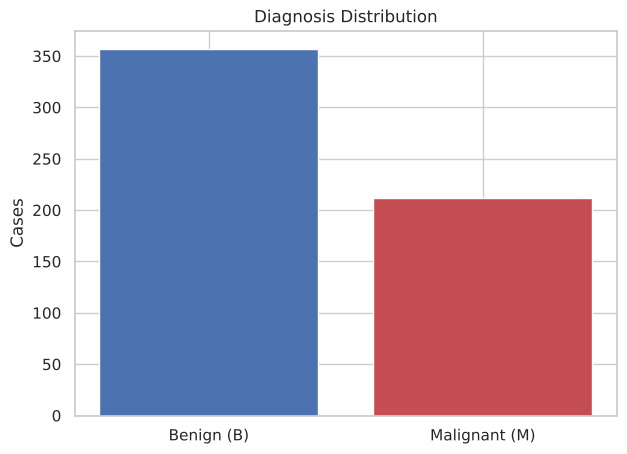

In [3]:
# Class counts
counts = y.map({0: LABELS[0], 1: LABELS[1]}).value_counts().reindex(LABELS)
print(counts)
print((counts / counts.sum() * 100).round(1).astype(str) + " %")

# Class balance plot
plt.figure(figsize=(7, 5))
plt.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
plt.title("Diagnosis Distribution")
plt.ylabel("Cases")
plt.show()

**Observation:** 357 B (62.7%) vs 212 M (37.3%). Moderate imbalance, so precision, recall, F1, AUC and a stratified split are used.

## Descriptive Statistics (mean, median, standard deviation)

In [4]:
# Mean, median, std
stats = X.describe().T
stats["median"] = X.median()
stats[["mean", "median", "std", "min", "max"]].round(3)

,mean,median,std,min,max
radius_mean,14.127,13.370,3.524,6.981,28.110
texture_mean,19.290,18.840,4.301,9.710,39.280
perimeter_mean,91.969,86.240,24.299,43.790,188.500
area_mean,654.889,551.100,351.914,143.500,2501.000
smoothness_mean,0.096,0.096,0.014,0.053,0.163
compactness_mean,0.104,0.093,0.053,0.019,0.345
concavity_mean,0.089,0.062,0.080,0.000,0.427
concave points_mean,0.049,0.034,0.039,0.000,0.201
symmetry_mean,0.181,0.179,0.027,0.106,0.304
fractal_dimension_mean,0.063,0.062,0.007,0.050,0.097


## Histograms

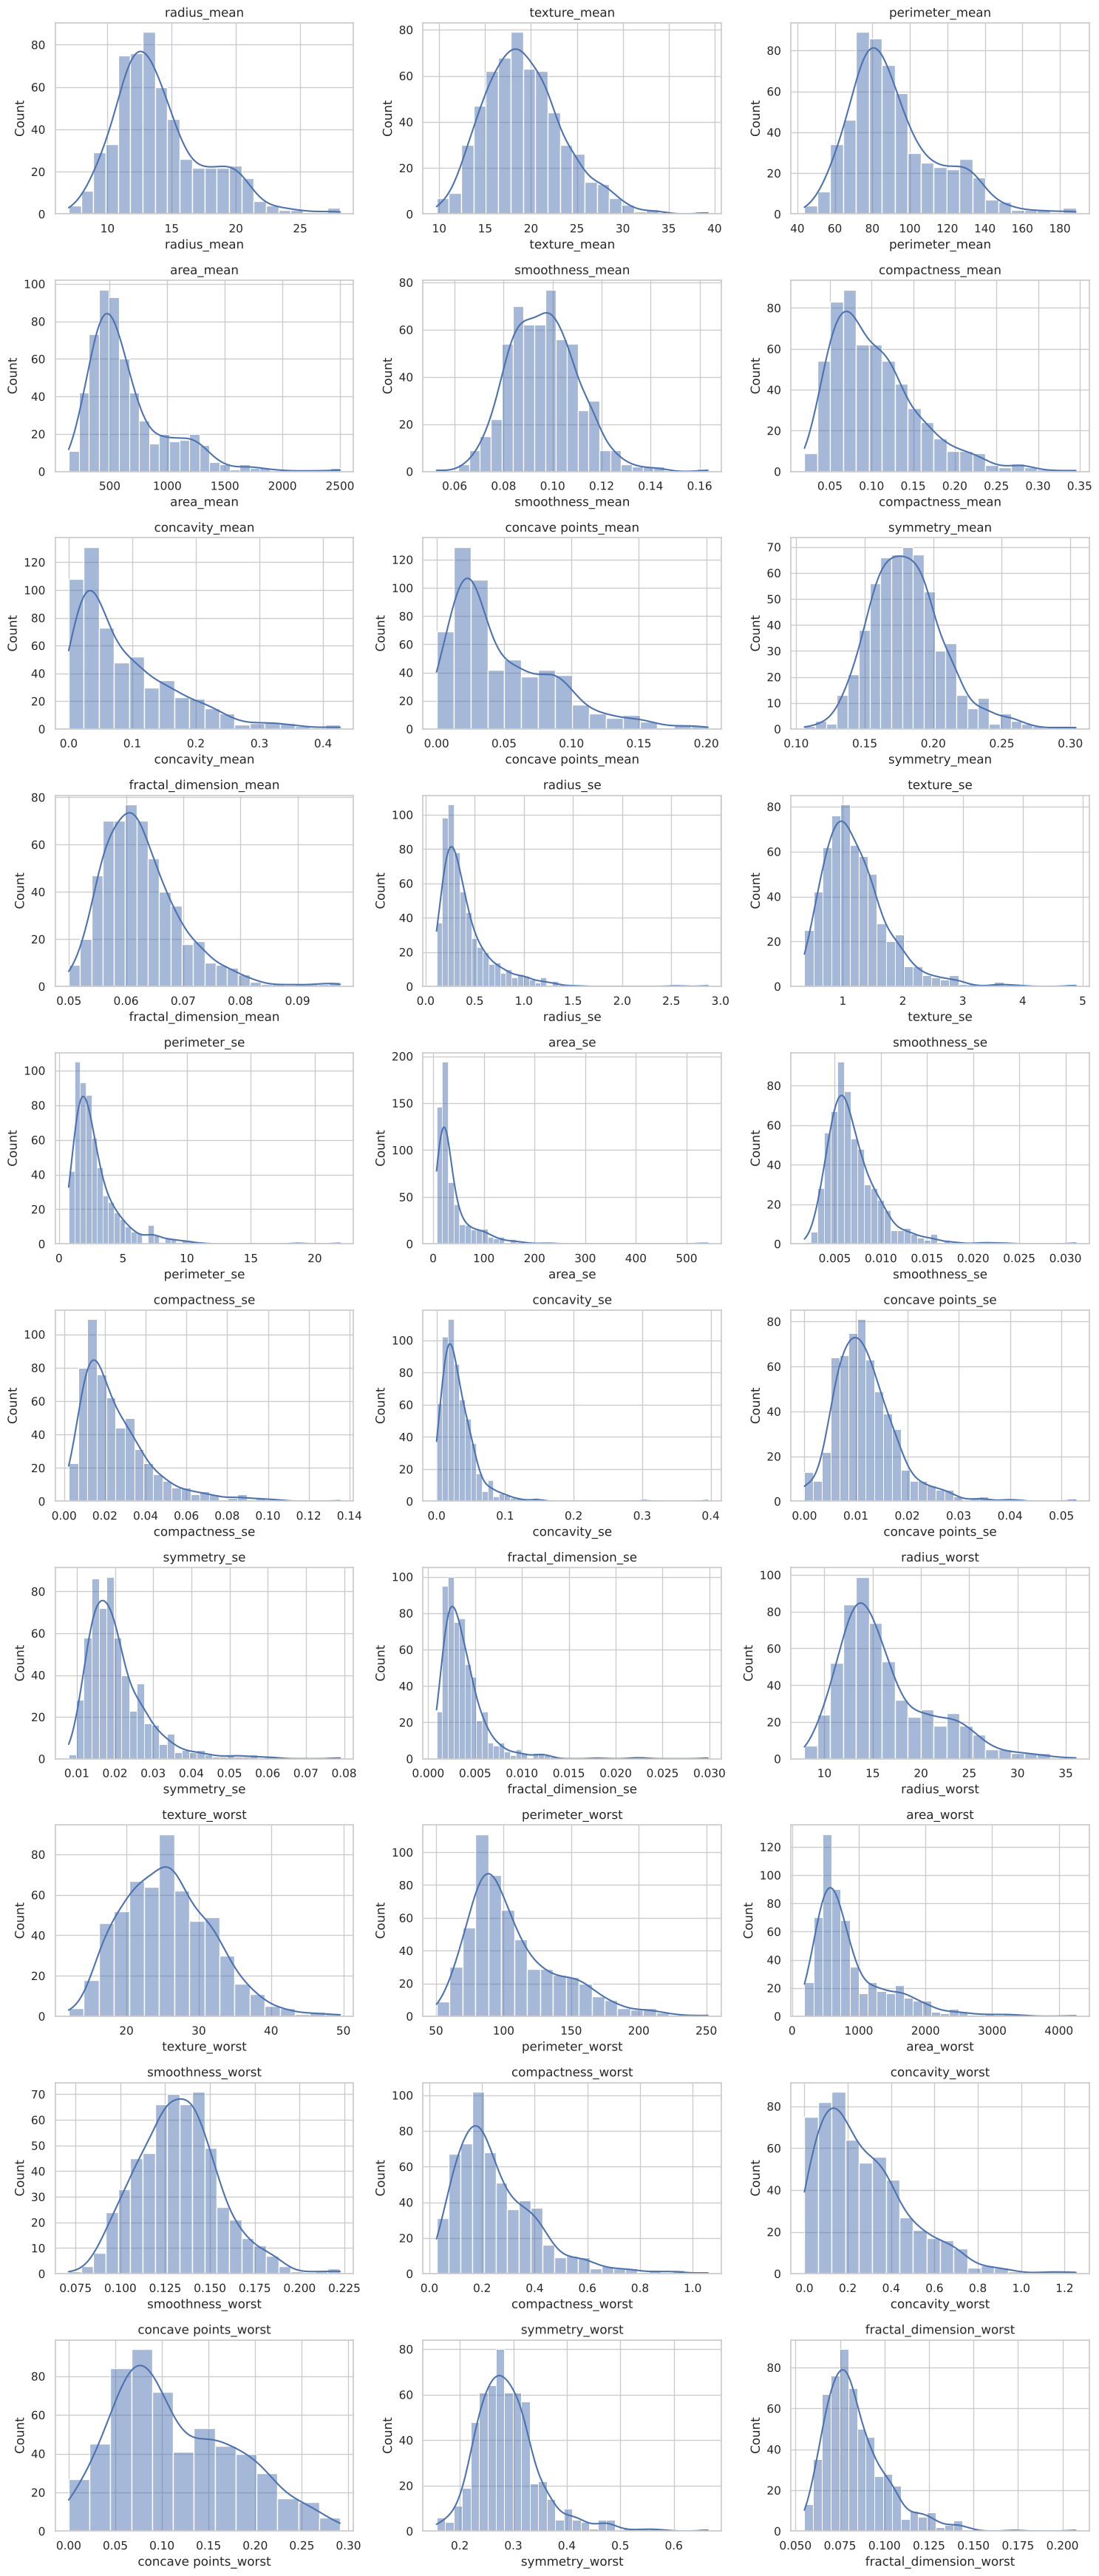

In [5]:
# Histograms per feature
ncols = 3
nrows = int(np.ceil(X.shape[1] / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = axes.ravel()
for ax, col in zip(axes, X.columns):
    sns.histplot(X[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)
for ax in axes[X.shape[1]:]:  # remove empty axes
    ax.remove()
plt.tight_layout()
plt.show()

## Box Plots

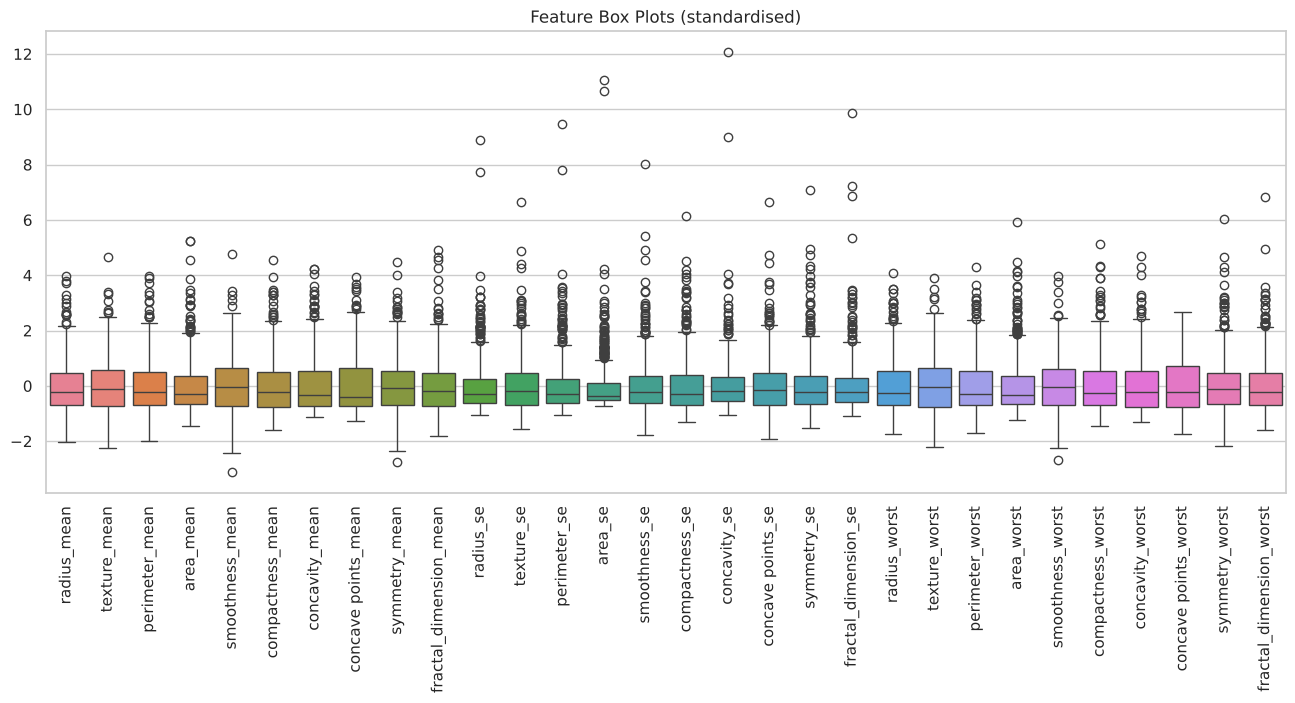

In [6]:
# Z-scores for a shared scale
Xz = (X - X.mean()) / X.std(ddof=0)
plt.figure(figsize=(16, 6))
sns.boxplot(data=Xz)
plt.xticks(rotation=90)
plt.title("Feature Box Plots (standardised)")
plt.show()

## Skewness and Outliers

In [7]:
# Skewness (> 1 = strong skew)
skew = X.skew()

# IQR outlier count
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
outliers = ((X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)).sum()

skew_out = pd.DataFrame({"skewness": skew.round(3), "n_outliers_IQR": outliers})
skew_out.sort_values("skewness", ascending=False).head(10)

,skewness,n_outliers_IQR
area_se,5.447,65
concavity_se,5.110,22
fractal_dimension_se,3.924,28
perimeter_se,3.444,38
radius_se,3.089,38
smoothness_se,2.314,30
symmetry_se,2.195,27
compactness_se,1.902,28
area_worst,1.859,35
fractal_dimension_worst,1.663,24


**Observation:** `*_se` and area features are strongly right-skewed with the most outliers. Outliers are kept, as they likely reflect real malignant cases.

## Correlation with the Target (Pearson)

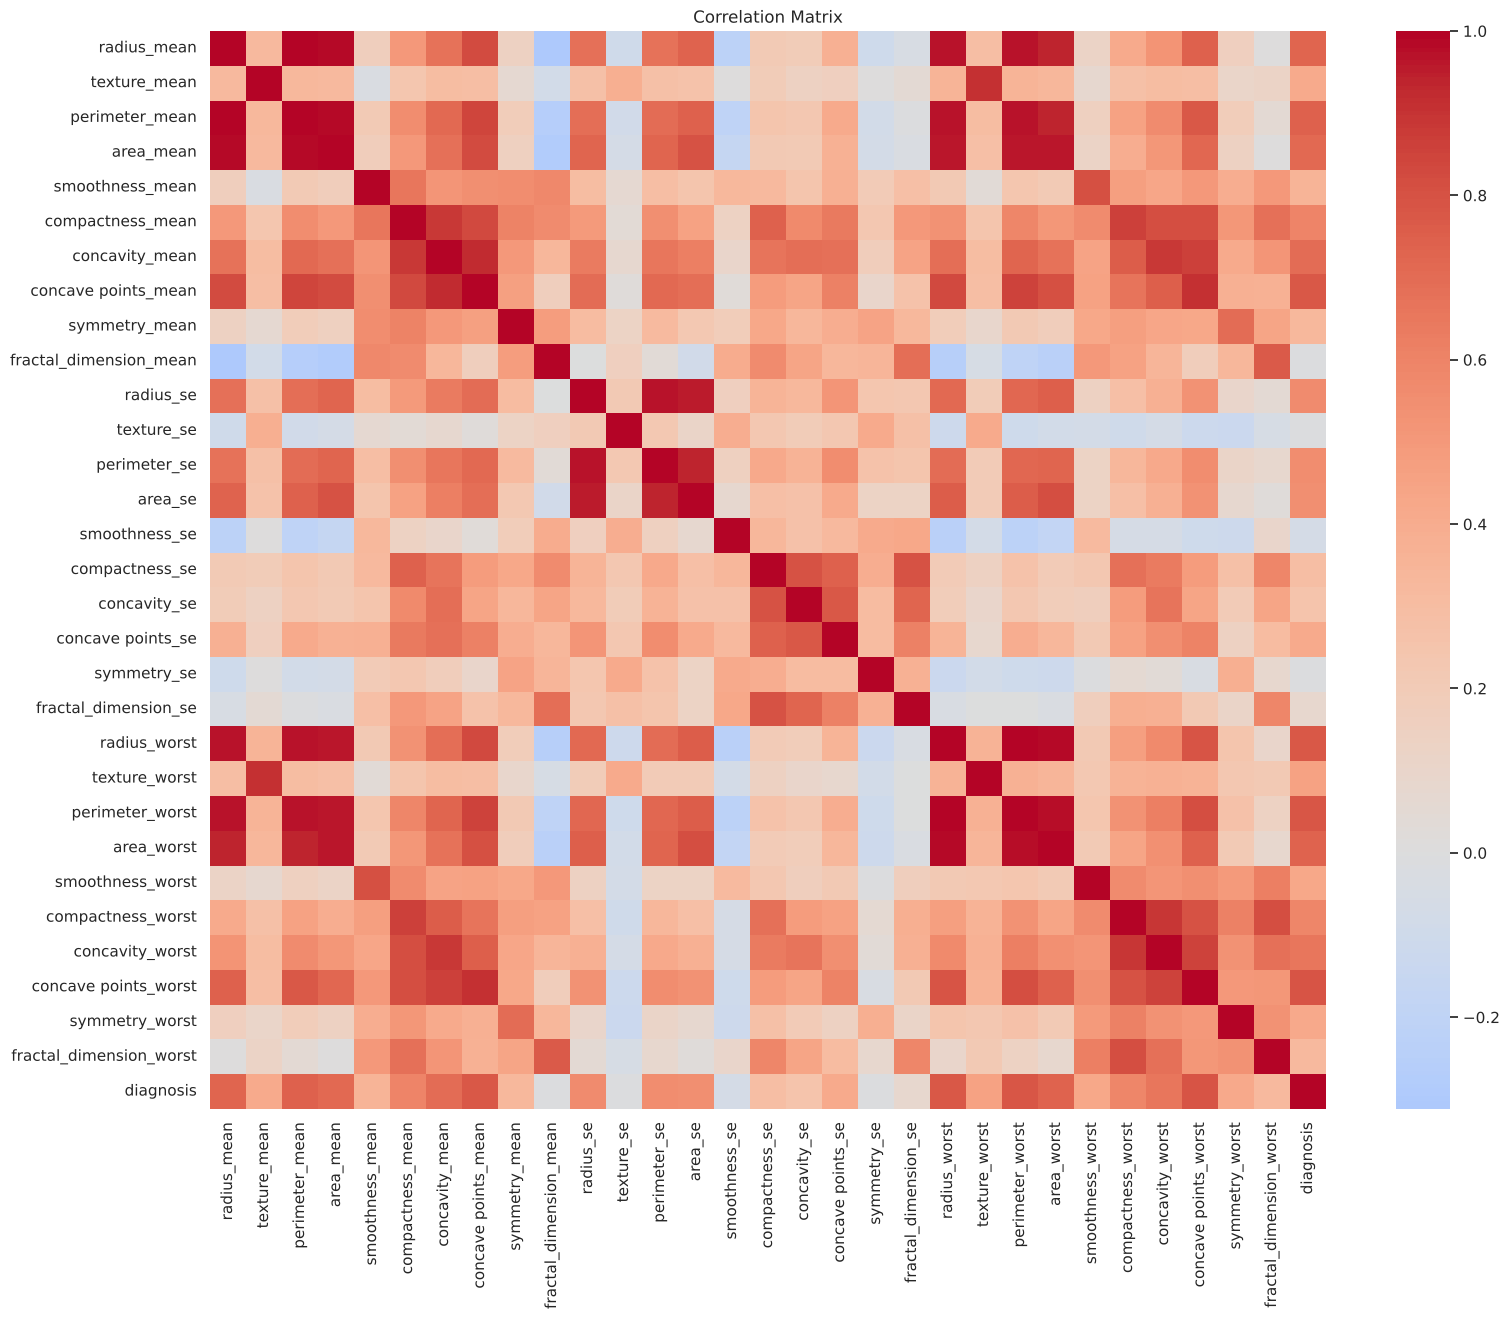

concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660
compactness_mean        0.597
compactness_worst       0.591
radius_se               0.567
perimeter_se            0.556
area_se                 0.548
Name: diagnosis, dtype: float64

In [8]:
# Pearson correlation
corr = X.assign(diagnosis=y).corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

# Top 15 with target
corr["diagnosis"].drop("diagnosis").sort_values(key=abs, ascending=False).head(15).round(3)

## Highly Correlated (Redundant) Features

In [9]:
# Redundant pairs (|r| >= 0.9)
fc = X.corr().abs()
upper = fc.where(np.triu(np.ones(fc.shape), k=1).astype(bool)).stack()
upper[upper >= 0.9].sort_values(ascending=False).round(3)

radius_mean          perimeter_mean          0.998
radius_worst         perimeter_worst         0.994
radius_mean          area_mean               0.987
perimeter_mean       area_mean               0.987
radius_worst         area_worst              0.984
perimeter_worst      area_worst              0.978
radius_se            perimeter_se            0.973
perimeter_mean       perimeter_worst         0.970
radius_mean          radius_worst            0.970
perimeter_mean       radius_worst            0.969
radius_mean          perimeter_worst         0.965
area_mean            radius_worst            0.963
                     area_worst              0.959
                     perimeter_worst         0.959
radius_se            area_se                 0.952
perimeter_mean       area_worst              0.942
radius_mean          area_worst              0.941
perimeter_se         area_se                 0.938
concavity_mean       concave points_mean     0.921
texture_mean         texture_wo

**Observation:** Most predictive: `concave points_worst`, `perimeter_worst`, `radius_worst` (r ≈ 0.78–0.79). Redundant: radius, perimeter and area (r ≈ 0.97–0.99).

# Task 2 – Data Preparation
## Missing Values

In [10]:
# Missing values
missing = X.isna().sum()
print("Total missing values:", missing.sum())
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

**Imputation:** No missing values. A median imputer is kept in the pipeline as a safeguard (robust to skew).

**Scaling:** `StandardScaler` for LR, SVM and KNN; trees are scale-invariant.

# Task 3 – Model Training
## Train/Test Split

**Split rationale:** 80/20 (455/114) balances training data and a reliable test set for a small dataset; stratified to keep the class ratio.

In [11]:
# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class ratio: ", y_test.value_counts(normalize=True).round(3).to_dict())

def pipe(model, scale=True):
    """Imputer -> optional scaler -> model."""
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("model", model)])

# Default models (max_iter for convergence, probability for AUC)
models = {
    "Logistic Regression": pipe(LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)),
    "SVM": pipe(SVC(probability=True, random_state=RANDOM_STATE)),
    "Decision Tree": pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
    "Random Forest": pipe(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    "KNN": pipe(KNeighborsClassifier()),
}

# Pipeline architecture
models["Logistic Regression"]

Train: (455, 30) | Test: (114, 30)
Train class ratio: {0: 0.626, 1: 0.374}
Test class ratio:  {0: 0.632, 1: 0.368}


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto accou

## Default Hyperparameters Used Initially

In [12]:
# Default hyperparameters
key_params = {
    "Logistic Regression": ["C", "solver", "max_iter"],
    "SVM": ["C", "kernel", "gamma", "probability"],
    "Decision Tree": ["criterion", "max_depth", "min_samples_split", "min_samples_leaf"],
    "Random Forest": ["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features"],
    "KNN": ["n_neighbors", "weights", "p", "metric"],
}
rows = []
for name, p in models.items():
    params = p.named_steps["model"].get_params()
    rows.append({"model": name, "default hyperparameters": ", ".join(f"{k}={params[k]}" for k in key_params[name])})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows)

,model,default hyperparameters
0,Logistic Regression,"C=1.0, solver=lbfgs, max_iter=3000"
1,SVM,"C=1.0, kernel=rbf, gamma=scale, probability=True"
2,Decision Tree,"criterion=gini, max_depth=None, min_samples_split=2, min_samples_leaf=1"
3,Random Forest,"n_estimators=100, max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features=sqrt"
4,KNN,"n_neighbors=5, weights=uniform, p=2, metric=minkowski"


## Cross-Validation and Training

In [13]:
# 5-fold CV, then fit on full training set
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_rows, fitted = [], {}
for name, model in models.items():
    r = cross_validate(clone(model), X_train, y_train, cv=cv,
                       scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    cv_rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["accuracy", "f1", "roc_auc"]}})
    fitted[name] = clone(model).fit(X_train, y_train)
cv_results = pd.DataFrame(cv_rows).sort_values("roc_auc", ascending=False)
cv_results.round(4)

,model,accuracy,f1,roc_auc
0,Logistic Regression,0.9736,0.9640,0.9958
1,SVM,0.9714,0.9610,0.9949
3,Random Forest,0.9648,0.9519,0.9889
4,KNN,0.9648,0.9510,0.9871
2,Decision Tree,0.9231,0.8962,0.9172


## Training Progress – Learning Curves

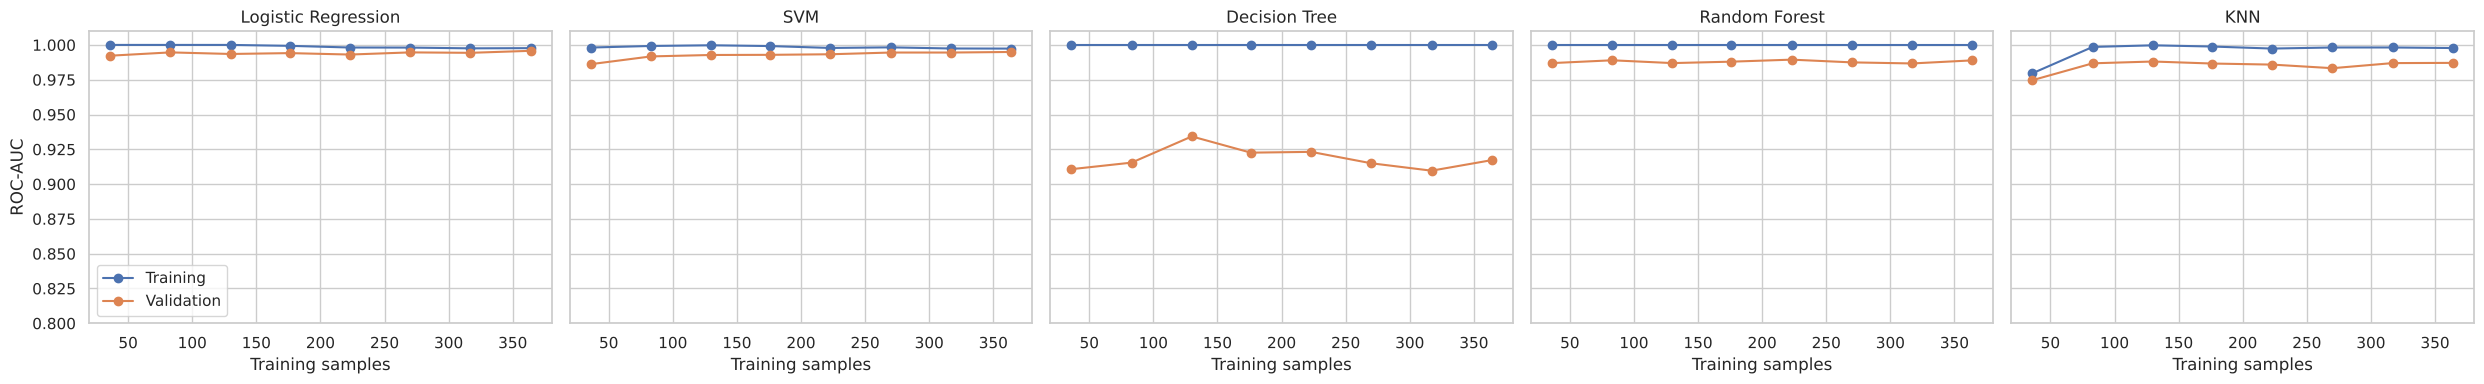

In [14]:
# Learning curves
fig, axes = plt.subplots(1, len(models), figsize=(5 * len(models), 4), sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    sizes, tr, va = learning_curve(clone(model), X_train, y_train, cv=cv, scoring="roc_auc",
                                   train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(sizes, tr.mean(axis=1), "o-", label="Training")
    ax.plot(sizes, va.mean(axis=1), "o-", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Training samples")
axes[0].set_ylabel("ROC-AUC")
axes[0].legend()
plt.ylim(0.8, 1.01)
plt.tight_layout()
plt.show()

**Observation:** LR and SVM generalise well; the Decision Tree overfits.

# Task 4 – Model Evaluation and Visualisation
## Test-Set Results (before tuning)

In [15]:
def evaluate(name, model, stage):
    """Test-set metrics."""
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]  # P(malignant)
    return {"model": name, "stage": stage,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred),
            "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, prob)}

baseline = pd.DataFrame([evaluate(n, m, "Before tuning") for n, m in fitted.items()])
baseline.round(4)

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Before tuning,0.9649,0.9750,0.9286,0.9512,0.9960
1,SVM,Before tuning,0.9737,1.0000,0.9286,0.9630,0.9947
2,Decision Tree,Before tuning,0.9298,0.9048,0.9048,0.9048,0.9246
3,Random Forest,Before tuning,0.9737,1.0000,0.9286,0.9630,0.9929
4,KNN,Before tuning,0.9561,0.9744,0.9048,0.9383,0.9823


## Baseline Comparison

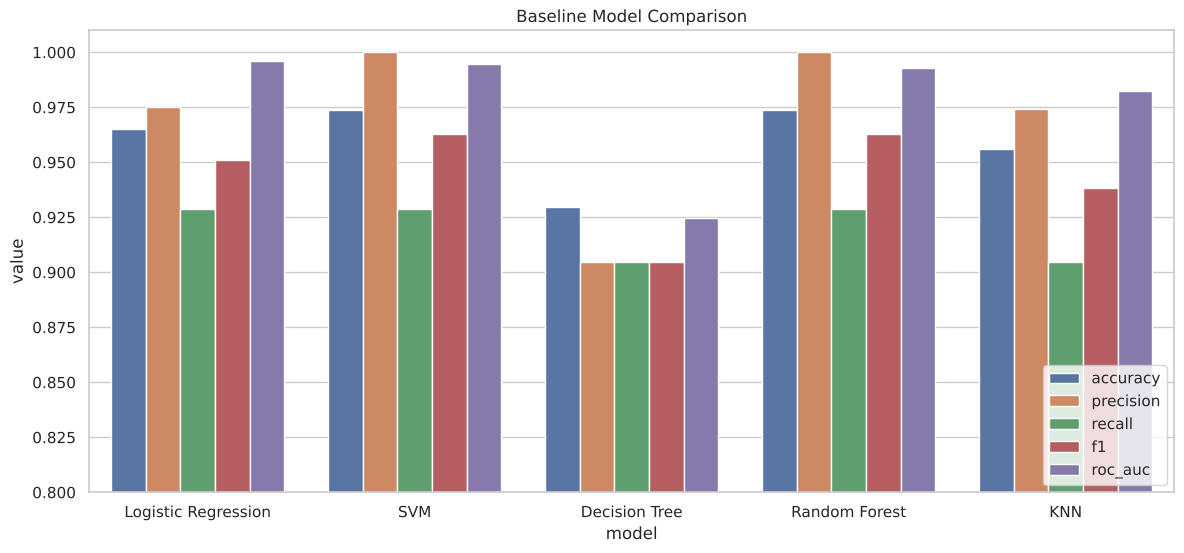

In [16]:
# Metric comparison
plt.figure(figsize=(14, 6))
sns.barplot(data=baseline.melt(id_vars=["model", "stage"], value_vars=METRICS),
            x="model", y="value", hue="variable")
plt.ylim(0.8, 1.01)
plt.title("Baseline Model Comparison")
plt.legend(loc="lower right")
plt.show()

## ROC Curves

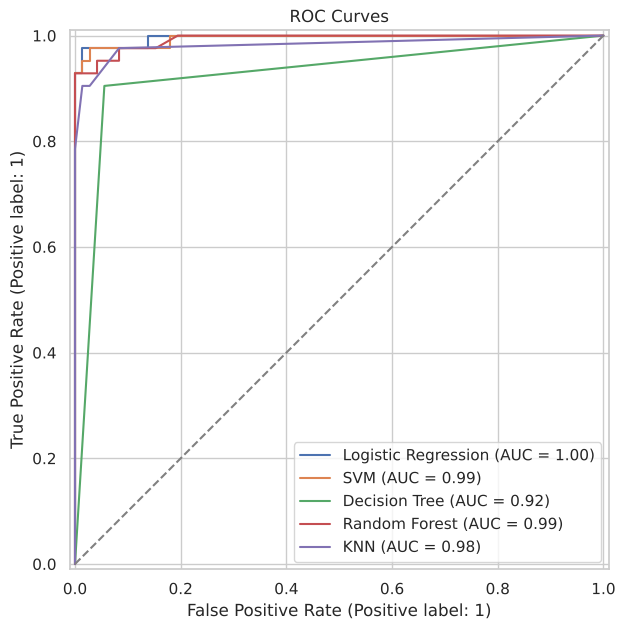

In [17]:
# ROC curves
fig, ax = plt.subplots(figsize=(8, 7))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("ROC Curves")
plt.show()

## Confusion Matrices

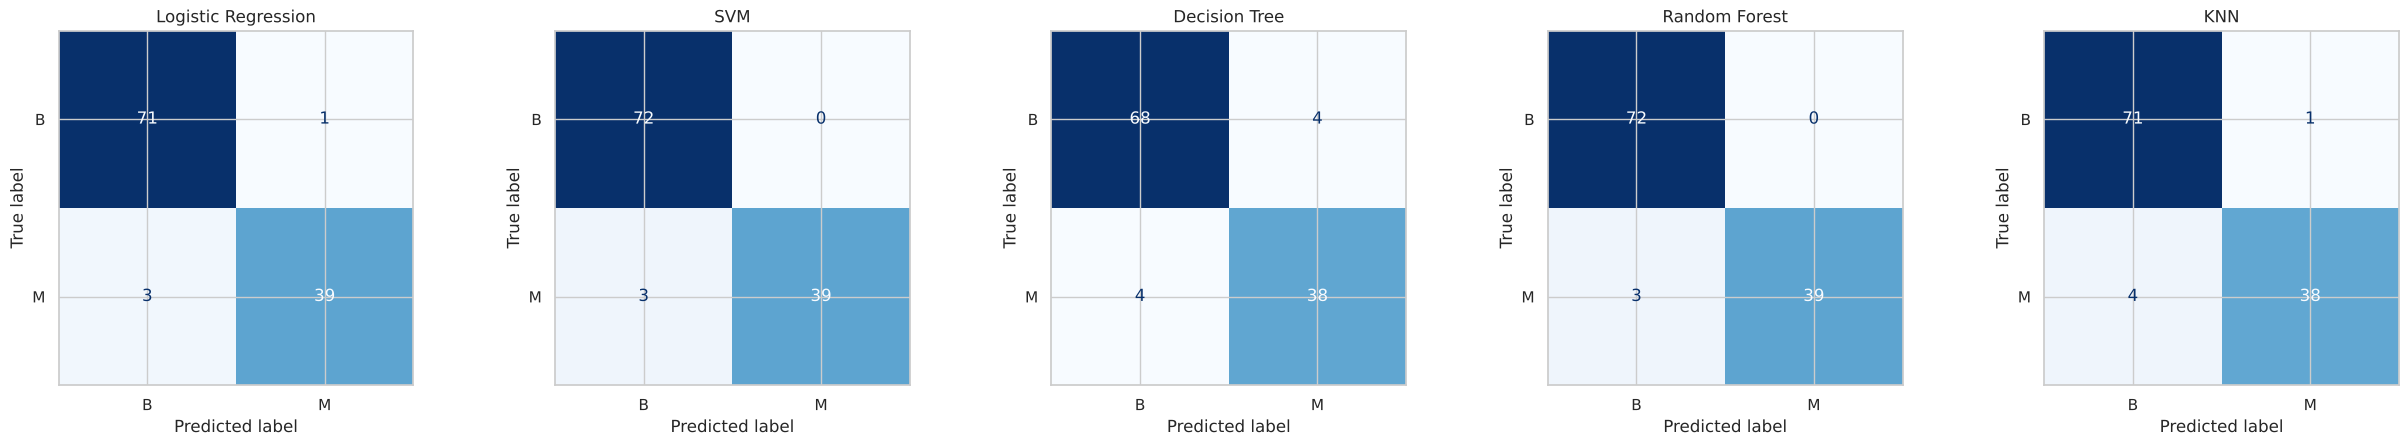

In [18]:
# Confusion matrices
fig, axes = plt.subplots(1, len(fitted), figsize=(5 * len(fitted), 4.5))
for ax, (name, model) in zip(axes, fitted.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["B", "M"],
                                          cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Best model:** LR and SVM have the highest AUC (≈ 0.996), as the scaled data is near-linearly separable. Decision Tree is weakest (overfitting). Malignant recall is prioritised, since missed cancers are costly. The top two by CV AUC are tuned.

## Hyperparameter Tuning (GridSearchCV)

In [19]:
# Search grids
grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10], "model__solver": ["liblinear", "lbfgs"]},
    "SVM": {"model__C": [0.1, 1, 10, 100], "model__kernel": ["linear", "rbf"], "model__gamma": ["scale", "auto"]},
    "Decision Tree": {"model__criterion": ["gini", "entropy"], "model__max_depth": [None, 3, 5, 8, 12],
                      "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4]},
    "Random Forest": {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 5, 10, 20],
                      "model__min_samples_split": [2, 5], "model__min_samples_leaf": [1, 2],
                      "model__max_features": ["sqrt", 0.5]},
    "KNN": {"model__n_neighbors": [3, 5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"], "model__p": [1, 2]},
}

tuned, best_cv = {}, {}
for name in cv_results["model"].head(2):  # top 2 by CV AUC
    search = GridSearchCV(clone(models[name]), grids[name], scoring="roc_auc",
                          cv=cv, n_jobs=-1).fit(X_train, y_train)
    tuned[name], best_cv[name] = search.best_estimator_, search.best_score_
    print(f"{name}: CV ROC-AUC={search.best_score_:.4f}  {search.best_params_}")

# Before vs after
comparison = pd.concat([baseline, pd.DataFrame([evaluate(n, m, "After tuning") for n, m in tuned.items()])])
comparison[comparison["model"].isin(tuned)].sort_values(["model", "stage"], ascending=[True, False]).round(4)

Logistic Regression: CV ROC-AUC=0.9959  {'model__C': 1, 'model__solver': 'liblinear'}


SVM: CV ROC-AUC=0.9949  {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}


,model,stage,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,Before tuning,0.9649,0.9750,0.9286,0.9512,0.9960
0,Logistic Regression,After tuning,0.9737,0.9756,0.9524,0.9639,0.9960
1,SVM,Before tuning,0.9737,1.0000,0.9286,0.9630,0.9947
1,SVM,After tuning,0.9737,1.0000,0.9286,0.9630,0.9947


## Before vs After Tuning

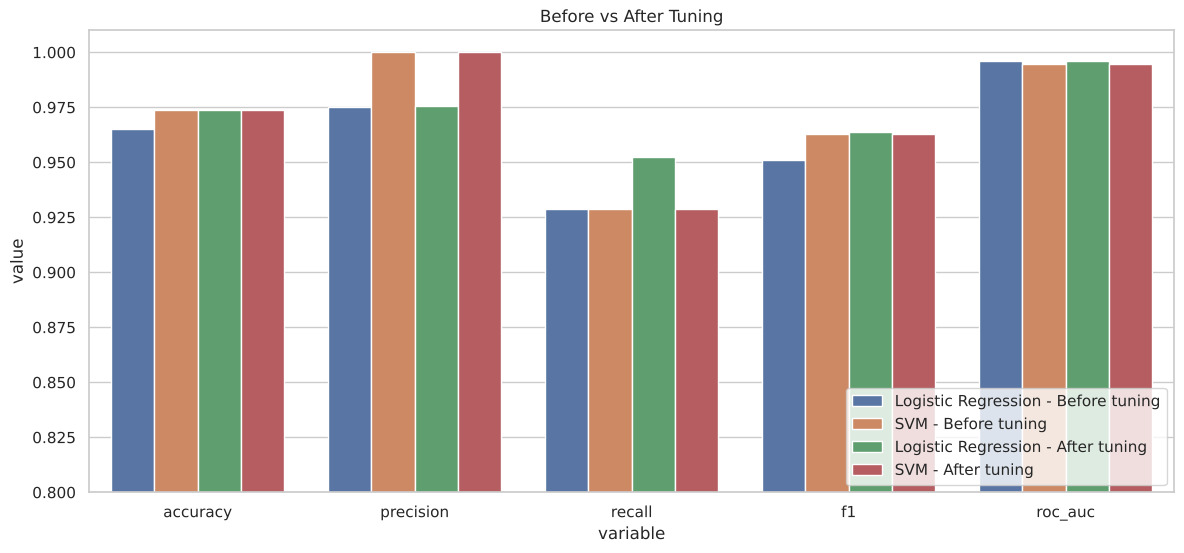

In [20]:
# Tuning comparison
plot_df = comparison[comparison["model"].isin(tuned)].melt(id_vars=["model", "stage"], value_vars=METRICS)
plot_df["run"] = plot_df["model"] + " - " + plot_df["stage"]
plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x="variable", y="value", hue="run")
plt.ylim(0.8, 1.01)
plt.title("Before vs After Tuning")
plt.legend(loc="lower right")
plt.show()

**Tuning effect:** LR accuracy 96.5% → 97.4%, malignant recall 0.929 → 0.952. SVM's best parameters equal its defaults, so no change.

## Final Model

In [21]:
# Highest CV AUC
scores = {n: best_cv.get(n, cv_results.set_index("model").loc[n, "roc_auc"]) for n in models}
final_name = max(scores, key=scores.get)
final_model = tuned.get(final_name, fitted[final_name])
print("Selected model:", final_name)
print(classification_report(y_test, final_model.predict(X_test), target_names=LABELS))

Selected model: Logistic Regression
               precision    recall  f1-score   support

   Benign (B)       0.97      0.99      0.98        72
Malignant (M)       0.98      0.95      0.96        42

     accuracy                           0.97       114
    macro avg       0.97      0.97      0.97       114
 weighted avg       0.97      0.97      0.97       114



## Feature Importance

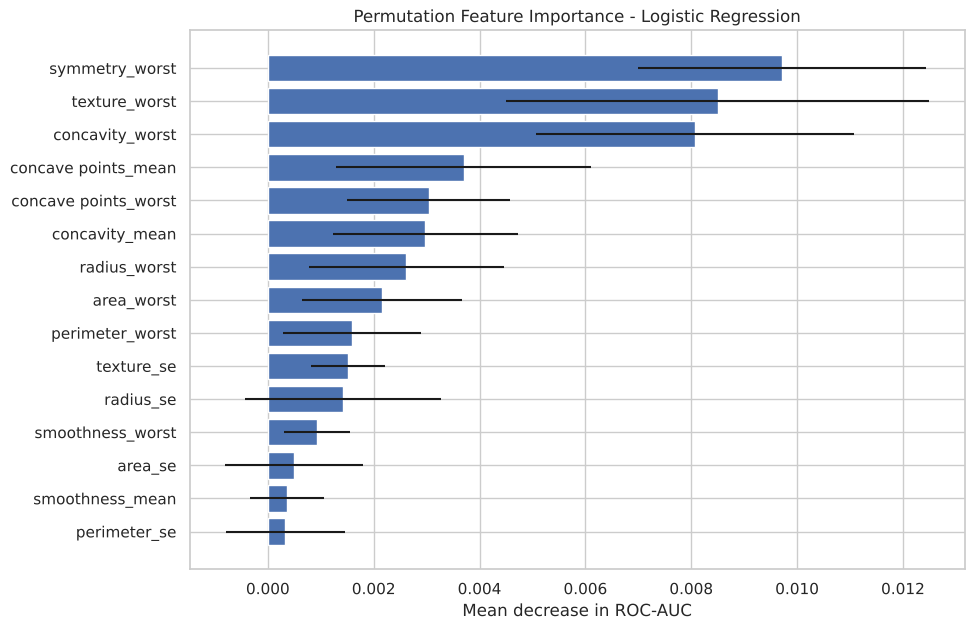

In [22]:
# Permutation importance
imp = permutation_importance(final_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({"feature": X.columns, "mean": imp.importances_mean, "std": imp.importances_std})
top = imp_df.nlargest(15, "mean").sort_values("mean")
plt.figure(figsize=(10, 7))
plt.barh(top["feature"], top["mean"], xerr=top["std"])
plt.title(f"Permutation Feature Importance - {final_name}")
plt.xlabel("Mean decrease in ROC-AUC")
plt.show()

# Task 5 – Conclusion and Future Work

- **Best model:** tuned Logistic Regression (accuracy 97.4%, malignant recall 0.95, AUC ≈ 0.996).
- **Key features:** `symmetry_worst`, `texture_worst` and `concavity_worst` (permutation importance).
- **Limitations:** 569 samples, single source, small test set, redundant features.
- **Generalisability:** external validation on other populations is required.
- **Future work:** neural networks, gradient boosting, feature selection/PCA, threshold tuning for higher recall.
- **Explainability:** SHAP/LIME to justify predictions to clinicians.